# 05 — Risk models (gene, regulon, program)

Follows the gbmMINER paper (Methods, "Risk prediction"):
- Survival → **GuanScore** (0–1); ridge regression predicts GuanScore; GuanScore > 0.5 = high risk
- TCGA split at random into **70% train / 10% validation / 20% test**
- Ridge penalty (alpha) **and number of features** chosen on the validation set; model trained on the train set
- Evaluated by C-index + KM on the **held-out TCGA test set** and an **independent cohort** (`VAL_NAME`; METABRIC for BRCA)
- Three models on the same splits: **gene** (expression), **regulon** (activity −1/0/1), **program** (activity −1/0/1)

Changes vs the first version of this notebook (and the GBM template):
- no in-sample C-index; program features are no longer pre-selected by Cox on all of TCGA
- program activity is built from **discrete regulon activity** in both TCGA and the validation cohort (previously eigengenes in TCGA vs discrete in the validation cohort)
- BRCA has only ~151 deaths, so one 20% test set (~30 events) is noisy: the split is repeated `N_REPEATS` times and mean ± sd test C-index is reported; the `FINAL_SEED` split gives the final model used for KM plots and METABRIC
- The validation cohort is scored on overall survival and, if it records cause of death, also on disease-specific survival (deaths from other causes censored)

Needs: `{prefix}_zscored.csv` from 01; `overExpressedMembers.csv`, `underExpressedMembers.csv`, `regulons.json`, `transcriptional_programs.json` from 02; `clinical_data.csv` from 03; `{val}_zscored.pkl` and `{val}_clinical.csv` from 04. Only the config cell needs editing for a new cancer.

In [1]:
import os
import json
import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import miner.miner as miner
from miner.miner import reduceModules, generateRegulonActivity, guanRank
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from scipy.stats import rankdata

warnings.filterwarnings('ignore')

# CANCER CONFIGURATION: the only lines to edit for a new cancer
CANCER     = "COAD"
base_dir   = r"causal_inf_new"

# this cancer's own folder: holds <prefix>_data, <prefix>_notebooks and <prefix>_output
cancer_dir = os.path.join(base_dir, CANCER.lower())

# this cancer's expression / mutation files (written by 01 and 02)
data_dir   = os.path.join(cancer_dir, f"{CANCER.lower()}_data")
prefix     = CANCER.lower()
output_dir = os.path.join(cancer_dir, f"{prefix}_output")

# Independent validation cohort
VALIDATION_COHORTS = {"BRCA": ("METABRIC", "brca_metabric"), "KIRC": ("EMTAB1980", "kirc_emtab1980"),
                      "LUAD": ("GSE72094", "luad_gse72094"), "COAD": ("GSE39582", "coad_gse39582"),
                      "UCEC": ("CPTAC", "ucec_cptac_2020")}
# A cancer that is not listed here has no independent cohort: the independent test is skipped and the
# results are marked "not externally validated" (validation_status.txt in the output folder)
VAL_NAME, _ = VALIDATION_COHORTS.get(CANCER, (None, None))
HAS_VALIDATION = VAL_NAME is not None
val = VAL_NAME.lower() if HAS_VALIDATION else "none"

risk_dir = os.path.join(output_dir, "risk_models")
os.makedirs(risk_dir, exist_ok=True)
miner_dir  = os.path.dirname(miner.__file__)
idmap_path = os.path.join(miner_dir, "data", "identifier_mappings.txt")

# Configuration:

# Repeated 70/10/20 splits (paper used one; BRCA has few deaths so one split is unreliable)
N_REPEATS  = 10 

# This split's model is the "final" one (TCGA test KM + METABRIC)
FINAL_SEED = 0

# List of ridge penalties to try
ALPHAS     = [0.1, 1, 5, 10, 50, 100, 500, 1000, 5000]

# Number of top-ranked features to try, chosen on validation
K_GRID     = {                                     
    "gene":    [10, 25, 50, 100, 250, 500, 1000, 2000],
    "regulon": [10, 25, 50, 100, 250, 500, 1000, 2000, "all"],
    "program": [5, 10, 25, 50, 100, "all"],
}

# program = +1/-1 if >=50% of its regulons are up/down (same as reduceModules in GBM)
PROGRAM_THRESHOLD = 0.5

# predicted GuanScore > 0.5 = high risk
RISK_CUTOFF = 0.5

MODELS = ["gene", "regulon", "program"]

In [2]:
# Load TCGA inputs
clinical = pd.read_csv(os.path.join(output_dir, "clinical_data.csv"), index_col=0)
over = pd.read_csv(os.path.join(output_dir, "overExpressedMembers.csv"),  index_col=0)
under = pd.read_csv(os.path.join(output_dir, "underExpressedMembers.csv"), index_col=0)
tcga_genes = pd.read_csv(os.path.join(data_dir, f"{prefix}_zscored.csv"), index_col=0)    # z-scored, symbols x patients

with open(os.path.join(output_dir, "transcriptional_programs.json")) as f:
    transcriptional_programs = json.load(f)
with open(os.path.join(output_dir, "regulons.json")) as f:
    regulon_modules = json.load(f)

program_list = [[int(r) for r in transcriptional_programs[k]] for k in sorted(transcriptional_programs, key=int)]

# Validation cohort expression is needed now too: the gene model may only use genes measured in both cohorts
mb_z = pd.read_pickle(os.path.join(output_dir, f"{val}_zscored.pkl")) if HAS_VALIDATION else None

print("clinical:", clinical.shape, "| regulon activity:", over.shape, "| TCGA genes:", tcga_genes.shape,
      "| programs:", len(program_list), "| validation cohort:", f"{VAL_NAME} {mb_z.shape}" if HAS_VALIDATION else "none")


clinical: (590, 2) | regulon activity: (7739, 458) | TCGA genes: (19752, 458) | programs: 216 | validation cohort: GSE39582 (21653, 566)


In [3]:
# GuanRank: 
# Converts survival to GuanScore before splitting into test, train, val cohorts
# C-index is always computed on the raw (OS_MONTHS, OS_STATUS), so this does not leak test outcomes into the evaluation metric.
patients = sorted(set(clinical.index) & set(over.columns) & set(tcga_genes.columns))
srv = clinical.loc[patients, ['OS_MONTHS', 'OS_STATUS']].dropna()

guan_path = os.path.join(output_dir, "guan_scores.csv")

# Reusing cached GuanScore:
if os.path.exists(guan_path):
    guan = pd.read_csv(guan_path, index_col=0).iloc[:, -1]
    print("Loaded cached GuanScores")

# Fresh run:
else:
    kmf = KaplanMeierFitter().fit(srv['OS_MONTHS'], srv['OS_STATUS'])
    km_surv = srv.copy()
    km_surv['kmEstimate'] = np.clip(kmf.survival_function_at_times(srv['OS_MONTHS']).values, 1e-6, None)
    guan = guanRank(km_surv)['GuanScore']
    guan.to_csv(guan_path)

srv = srv.loc[srv.index.intersection(guan.index)]
srv['GuanScore'] = guan.loc[srv.index]
patients = list(srv.index)
print(f"TCGA patients: {len(patients)} | deaths: {int(srv['OS_STATUS'].sum())}")

TCGA patients: 435 | deaths: 98


In [4]:
# Builds feature matrix that program risk model is trained on
def program_activity(reg_act, programs, threshold=PROGRAM_THRESHOLD):

    '''

    Converts discrete regulon activity into discrete program activity using miner's reduceModules. The same function is used
    for TCGA and the validation cohort so the model sees identically built features.

    Args: reg_act (df), shape (n_regulons, n_patients). Index is regulon ID (int), contains regulon activity (1/0/-1)
          programs (list of lists). Regulon IDs of each program
          threshold (float). Fraction of a program's regulons that must agree for the program to be active (default 0.5)

    Returns: prog (df), shape (n_programs, n_patients). Index is program number, contains program activity (1/0/-1)

    '''

    # Takes regulon activity as input
    # Keeps only those regulons which are in activity table in each program
    # Nested list of the form [[r1p1, r2p1, ...]]
    present = [[r for r in p if r in reg_act.index] for p in programs]

    # Only keep programs with >= 1 regulon
    keep    = [i for i, p in enumerate(present) if p]

    # For each program (row) and patient (column) avgs program activity
    # >= 50% of a program's regulons overactive --> 1, >= 50% underactive --> -1, else 0
    prog = reduceModules(df=reg_act, programs=[present[i] for i in keep],
                         states=[list(reg_act.columns)], stateThreshold=threshold)
    prog.index = keep
    return prog.reindex(range(len(programs))).fillna(0.0)

# Regulon activity = overexpressed - underexpressed
reg_act_tcga = (over.astype(int) - under.astype(int))

# Converts index to integer
reg_act_tcga.index = reg_act_tcga.index.astype(int)

# Builds program activity
prog_act_tcga = program_activity(reg_act_tcga, program_list)

# For gene model, which only uses genes in both main and validation cohorts
shared_genes = tcga_genes.index.intersection(mb_z.index) if HAS_VALIDATION else tcga_genes.index

X_tcga = {

    # (1091 patients, 17802 gene z-scores)
    "gene":    tcga_genes.loc[shared_genes, patients].T,

    # (1091 patients, 8116 regulons) (−1/0/+1)
    "regulon": reg_act_tcga.loc[:, patients].T,

    # (1091 patients, 211 programs) (-1/0/+1)
    "program": prog_act_tcga.loc[:, patients].T,
}

for m in MODELS:
    print(f"{m:8s} features: {X_tcga[m].shape[1]:>6}  | non-zero fraction: {(X_tcga[m].values != 0).mean():.3f}")

gene     features:  16696  | non-zero fraction: 1.000
regulon  features:   7739  | non-zero fraction: 0.400
program  features:    216  | non-zero fraction: 0.326


In [5]:
# Train/val/test split

# What to predict i.e. GuanScore or risk score (0-1)
y_all   = srv['GuanScore']

# Event: dead(1) or not (0)
evt_all = srv['OS_STATUS'].astype(int)


def split_70_10_20(seed):

    '''

    Takes 70% train, 20% test, 10% val. stratify = evt_all keeps share of deaths (14%) identical in each split 
    so that train, test (smaller splits) have enough deaths to be useful

    Args: seed (int). Fixes random seed for reproducibility 

    Returns: tr (list), va(list), te(list). All 3 lists of patient IDs with same share of deaths

    '''
    
    tr, rest = train_test_split(patients, train_size=0.70, stratify=evt_all, random_state=seed)
    va, te   = train_test_split(rest, train_size=1/3, stratify=evt_all.loc[rest], random_state=seed)
    return tr, va, te


def rank_features(X, y):
 
    ''' 
    
    Finds Spearman correlation coefficient between each feature and GuanScore. Returns features sorted by |Spearman| in descending order
    
    Args: X (np.array), shape (n_train, n_features). Contains gene/ regulon/ program scores (continuous or 1/0/-1)
          y (np.array), shape (n_train,). Contains known GuanScore (0-1)

    Returns: np.array, shape (n_features,). Contains each feature column sorted by |Spearman| in descending order

    '''

    # Converts features into their ranks (lowet value --> 1, and so on) where tied values share avg of their ranks
    # E.g.: [0.5, 1, 1, 2] --> [1, 1.5, 1.5, 4]
    # axis = 0 means this is done for every column
    Xr = rankdata(X, axis=0); yr = rankdata(y)

    # Mean-centering
    Xr = Xr - Xr.mean(0); yr = yr - yr.mean()

    # Division by s.d
    denom = np.sqrt((Xr ** 2).sum(0) * (yr ** 2).sum())

    # This gives 0 instead of error for features that don't vary
    rho = np.divide(Xr.T @ yr, denom, out=np.zeros(X.shape[1]), where=denom > 0)
    return np.argsort(-np.abs(rho))

def cindex(pred, ids, time_col='OS_MONTHS', event_col='OS_STATUS', table=None):

    '''

    Returns c-index (concordance index) which is computed on test or val patients. Measures how well model
    ranks patients by risk (0.5 = random, 1.0 = perfect).

    Args: pred (np.array), shape (n_test/n_val,). Contains predicted GuanScore
          ids (np.array), shape (n_test/n_val,). Contains patient IDs in same order as pred
          time_col/event_col (str). Names of the survival time and event columns in table to score against
          table (df). Index is patient ID, contains the above 2 columns. The default is the TCGA srv table

    Returns: concordance_index (float)

    '''
    table = srv if table is None else table
    return concordance_index(table.loc[ids, time_col], -np.asarray(pred), table.loc[ids, event_col])

def fit_one_split(model_name, seed):

    '''
    
    Fits model on one split of data (train/val/test). Ranks features on train, picks k (number of features to use) and alpha (ridge penalty)
    on validation, refits on train, scores on test.
    
    Args: model_name (str), "gene", "program" or "regulon". Picks the feature matrix to use for ridge regression
          seed (int). Fixes random seed for reproducibility.

    Returns: result (dict) with keys
    
             model (str) "gene", "regulon" or "program"
             seed (int) which random split was used
             k (int)number of top-ranked features kept (chosen on validation)
             alpha (float)  ridge penalty (chosen on validation)
             val_cindex (float)  C-index on the validation set (biased upward, not reported)
             test_cindex (float)  C-index on the held-out test set (the reported number)
             features (list)   names of the k selected features (gene symbols, regulon IDs or program numbers)
             ridge (sklearn Ridge)  model fitted on the training set
             split (tuple of 3 lists)  (train, validation, test) patient IDs

    '''
    
    Xdf = X_tcga[model_name]
    tr, va, te = split_70_10_20(seed)
    Xtr, Xva, Xte = Xdf.loc[tr].values, Xdf.loc[va].values, Xdf.loc[te].values
    ytr = y_all.loc[tr].values
    order = rank_features(Xtr, ytr)

    best = (-np.inf, None, None)
    for k in K_GRID[model_name]:
        kk = Xdf.shape[1] if k == "all" else k
        if kk > Xdf.shape[1]:
            continue
        cols = order[:kk]
        for a in ALPHAS:
            ci_va = cindex(Ridge(alpha=a).fit(Xtr[:, cols], ytr).predict(Xva[:, cols]), va)
            if ci_va > best[0]:
                best = (ci_va, kk, a)

    ci_va, k_best, a_best = best
    cols  = order[:k_best]
    model = Ridge(alpha=a_best).fit(Xtr[:, cols], ytr)         # trained on the 70% only (as in the paper)
    ci_te = cindex(model.predict(Xte[:, cols]), te)
    return {"model": model_name, "seed": seed, "k": k_best, "alpha": a_best,
            "val_cindex": ci_va, "test_cindex": ci_te,
            "features": list(Xdf.columns[cols]), "ridge": model, "split": (tr, va, te)}

In [6]:
# Repeated splits: actual TCGA test C-index for each model
start = time.time()

# One result dict per (model, split), as returned by fit_one_split
runs = []

# For each of the N_REPEATS random splits, all 3 models are fitted on the same split
for seed in range(N_REPEATS):
    for m in MODELS:
        runs.append(fit_one_split(m, seed))

    # Progress: test C-index, chosen k and alpha of the 3 models just fitted (last 3 entries of runs)
    print(f"split {seed+1}/{N_REPEATS} done ({(time.time()-start)/60:.1f} min) | " +
          " | ".join(f"{r['model']} test C={r['test_cindex']:.3f} (k={r['k']}, a={r['alpha']})" for r in runs[-3:]))

# Table with one row per model per split, without the bulky entries (feature lists, fitted models, patient lists)
runs_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("features", "ridge", "split")} for r in runs])
runs_df.to_csv(os.path.join(risk_dir, "tcga_repeated_splits.csv"), index=False)

# Mean and s.d of validation and test C-index across the splits, per model
# Validation C-index is biased upward (k and alpha were picked to maximise it), so the test C-index is the one to report
summary = runs_df.groupby("model")[["val_cindex", "test_cindex"]].agg(["mean", "std"]).loc[MODELS].round(3)
print("\nTCGA held-out test C-index over", N_REPEATS, "random 70/10/20 splits:")
print(summary)

split 1/10 done (0.1 min) | gene test C=0.550 (k=100, a=500) | regulon test C=0.520 (k=25, a=0.1) | program test C=0.401 (k=5, a=0.1)
split 2/10 done (0.1 min) | gene test C=0.556 (k=1000, a=5000) | regulon test C=0.414 (k=100, a=0.1) | program test C=0.511 (k=100, a=10)
split 3/10 done (0.1 min) | gene test C=0.532 (k=50, a=500) | regulon test C=0.644 (k=500, a=1) | program test C=0.536 (k=5, a=1000)
split 4/10 done (0.2 min) | gene test C=0.525 (k=1000, a=1) | regulon test C=0.510 (k=7739, a=50) | program test C=0.488 (k=10, a=1000)
split 5/10 done (0.2 min) | gene test C=0.586 (k=500, a=0.1) | regulon test C=0.498 (k=2000, a=0.1) | program test C=0.470 (k=5, a=0.1)
split 6/10 done (0.3 min) | gene test C=0.531 (k=2000, a=0.1) | regulon test C=0.549 (k=2000, a=100) | program test C=0.558 (k=50, a=0.1)
split 7/10 done (0.3 min) | gene test C=0.739 (k=2000, a=5000) | regulon test C=0.714 (k=50, a=10) | program test C=0.585 (k=5, a=100)
split 8/10 done (0.4 min) | gene test C=0.600 (k=5

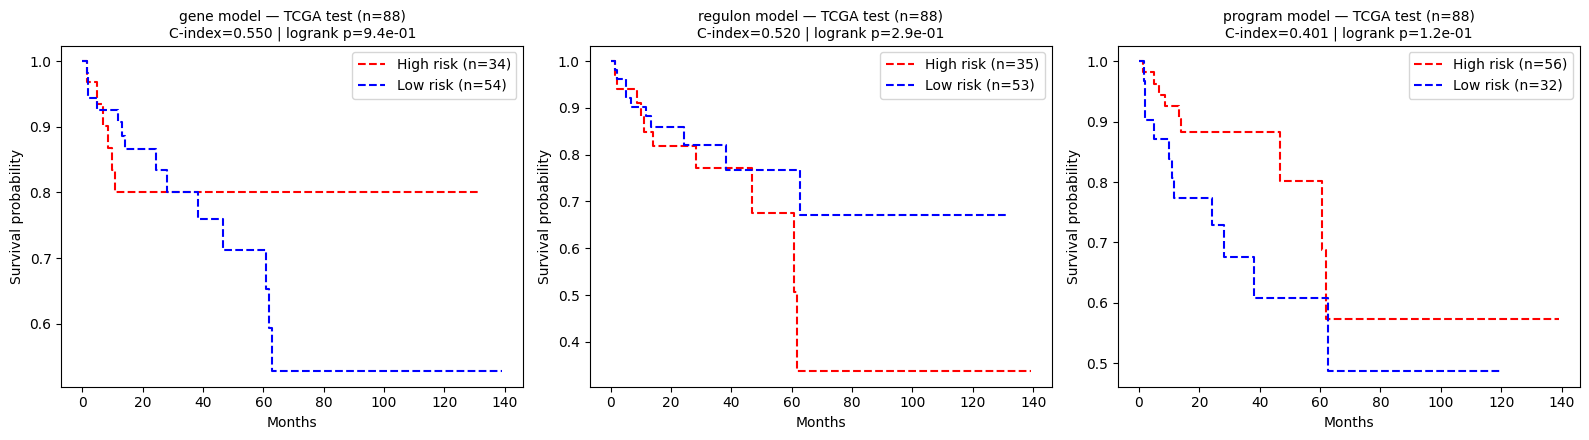

gene     final: k=100, alpha=500, val C=0.758, test C=0.550
regulon  final: k=25, alpha=0.1, val C=0.734, test C=0.520
program  final: k=5, alpha=0.1, val C=0.804, test C=0.401


In [7]:
# Final models (FINAL_SEED split) and KM curves on the TCGA test set, as in paper Figure 4

# The 3 models fitted on the FINAL_SEED split, as {model name: result dict}
final = {r["model"]: r for r in runs if r["seed"] == FINAL_SEED}

# Save the fitted models with their selected features, settings and split so they can be reused without refitting
with open(os.path.join(risk_dir, "final_models.pkl"), "wb") as f:
    pickle.dump({m: {k: final[m][k] for k in ("ridge", "features", "k", "alpha", "split")} for m in MODELS}, f)

def km_panel(ax, pred, table, time_col, event_col, title):

    '''

    Splits patients into high risk (pred > RISK_CUTOFF) and low risk, draws both Kaplan-Meier curves on one panel
    and computes the C-index and logrank p-value.

    Args: ax (matplotlib axis). Panel to draw on
          pred (np.array), shape (n_patients,). Contains predicted GuanScore, one per row of table in the same order
          table (df), shape (n_patients, >= 2). Indexed by patient ID, contains time_col and event_col
          time_col (str). Name of survival time column
          event_col (str). Name of event column (1/0)
          title (str). Plot title

    Returns: ci (float) C-index of pred on table
             p (float) logrank p-value between high-risk and low-risk groups (NaN if all patients fall in one group)

    '''

    # Attach patient IDs to the predictions so they line up with the survival table
    pred = pd.Series(np.asarray(pred), index=table.index)

    # High risk: predicted GuanScore above the cutoff. Low risk: everyone else
    hi, lo = table[pred > RISK_CUTOFF], table[pred <= RISK_CUTOFF]

    # C-index uses the full ranking of patients (-pred because a high GuanScore means short survival)
    ci = concordance_index(table[time_col], -pred, table[event_col])

    # If every patient falls in one group there is nothing to compare
    if len(hi) == 0 or len(lo) == 0:
        ax.set_title(f"{title}\nall patients in one group (C={ci:.3f})"); return ci, np.nan

    # Logrank test: are the survival curves of the two groups different?
    p = logrank_test(hi[time_col], lo[time_col], hi[event_col], lo[event_col]).p_value

    # One Kaplan-Meier curve per group
    for grp, lab, col in ((hi, "High risk", "red"), (lo, "Low risk", "blue")):
        KaplanMeierFitter().fit(grp[time_col], grp[event_col], label=f"{lab} (n={len(grp)})").plot_survival_function(
            ax=ax, ci_show=False, color=col, linestyle='--')

    ax.set_title(f"{title}\nC-index={ci:.3f} | logrank p={p:.1e}", fontsize=10)
    ax.set_xlabel("Months"); ax.set_ylabel("Survival probability")
    return ci, p

# One panel per model: predict the 20% test patients of the final split (never used for fitting or tuning) and plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, MODELS):

    # Final model for m and its test patient IDs (split = (train, val, test))
    r  = final[m]; te = r["split"][2]

    # Predict using only the features this model selected
    pred = r["ridge"].predict(X_tcga[m].loc[te, r["features"]].values)
    km_panel(ax, pred, srv.loc[te], 'OS_MONTHS', 'OS_STATUS', f"{m} model — TCGA test (n={len(te)})")

plt.tight_layout(); plt.savefig(os.path.join(risk_dir, "km_tcga_test.pdf"), dpi=300); plt.show()

# Chosen settings and scores of the final models
for m in MODELS:
    r = final[m]
    print(f"{m:8s} final: k={r['k']}, alpha={r['alpha']}, val C={r['val_cindex']:.3f}, test C={r['test_cindex']:.3f}")

### Cross-validated predictions for all TCGA patients (better-powered KM)
A single 20% test set has only ~30 deaths, so its log-rank test is underpowered. Here every TCGA patient gets an **out-of-fold** prediction: 5-fold stratified CV; inside each training fold, 12.5% is held out to choose alpha and the number of features (same grid and ranking as above), the model is fit on the rest, then it predicts the unseen fold. The KM/log-rank then uses all ~1,091 patients and ~151 deaths while staying fully out-of-sample. Report this alongside (not instead of) the 70/10/20 results above.

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


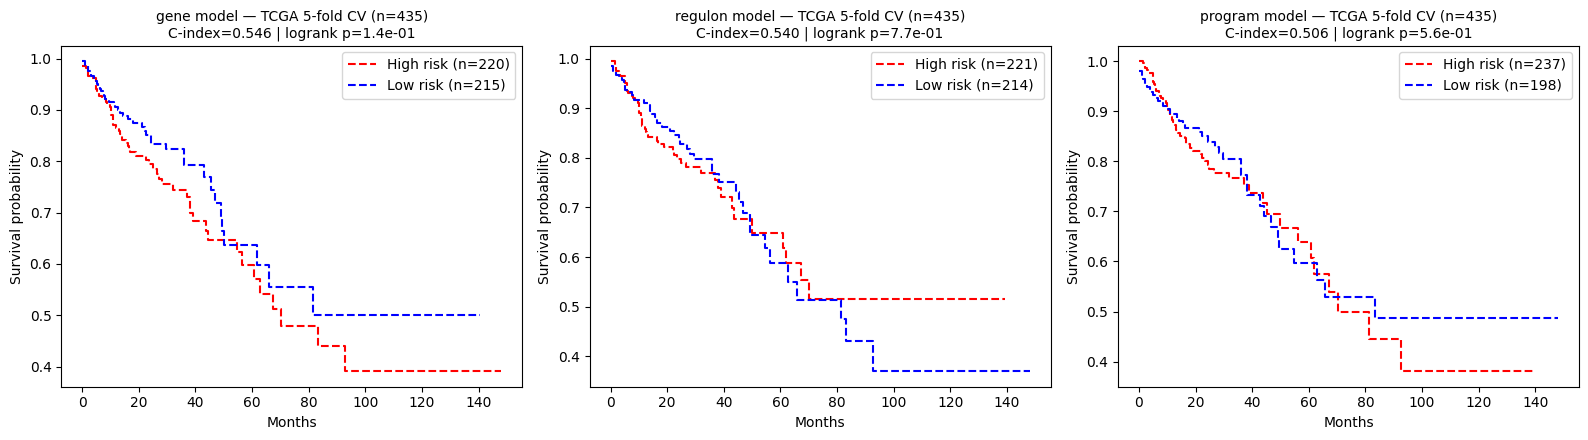

          OOF_C  logrank_p  fold_C_mean  fold_C_sd  high_risk_n
model                                                          
gene     0.5458     0.1367       0.5551     0.0665          220
regulon  0.5396     0.7714       0.5451     0.0466          221
program  0.5061     0.5619       0.5169     0.0583          237


In [8]:
# Cross-validation: out-of-fold prediction for every TCGA patient
from sklearn.model_selection import StratifiedKFold

# Number of folds and random seed
N_FOLDS = 5
CV_SEED = 0

def tune_fit_predict(model_name, train_ids, test_ids, seed):

    '''

    One fold of cross-validation. Holds out 12.5% of train_ids as an inner validation set to pick k (number of features to use)
    and alpha (ridge penalty), fits on the rest and predicts test_ids. test_ids are never used for fitting or tuning.

    Args: model_name (str), "gene", "program" or "regulon". Picks the feature matrix to use for ridge regression
          train_ids (list). Patient IDs of the training folds
          test_ids (list). Patient IDs of the held-out fold
          seed (int). Fixes random seed of the inner train/val split for reproducibility

    Returns: pred (np.array), shape (n_test,). Predicted GuanScore for test_ids in the same order
             k (int) number of features chosen on the inner validation set
             alpha (float) ridge penalty chosen on the inner validation set

    '''

    Xdf = X_tcga[model_name]

    # Inner split of the training folds: 87.5% to fit, 12.5% to choose k and alpha (same share of deaths in both)
    in_tr, in_va = train_test_split(train_ids, test_size=0.125, stratify=evt_all.loc[train_ids], random_state=seed)
    Xtr, Xva = Xdf.loc[in_tr].values, Xdf.loc[in_va].values
    ytr = y_all.loc[in_tr].values

    # Rank features using the inner training patients only
    order = rank_features(Xtr, ytr)

    # Try every (k, alpha) and keep the pair with the best C-index on the inner validation set
    best = (-np.inf, None, None)
    for k in K_GRID[model_name]:

        # "all" means every feature. Grid values larger than the number of features are skipped
        kk = Xdf.shape[1] if k == "all" else k
        if kk > Xdf.shape[1]:
            continue
        cols = order[:kk]
        for a in ALPHAS:
            ci_va = cindex(Ridge(alpha=a).fit(Xtr[:, cols], ytr).predict(Xva[:, cols]), in_va)
            if ci_va > best[0]:
                best = (ci_va, kk, a)

    # Refit with the best settings and predict the held-out fold
    cols = order[:best[1]]
    model = Ridge(alpha=best[2]).fit(Xtr[:, cols], ytr)
    return model.predict(Xdf.loc[test_ids].values[:, cols]), best[1], best[2]

# Splits patients into N_FOLDS parts with the same share of deaths in each
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_SEED)
pat_arr = np.array(patients)

# Out-of-fold predictions: one per patient per model, filled in fold by fold
oof = {m: pd.Series(np.nan, index=patients) for m in MODELS}

# Chosen settings and C-index of every fold
fold_log = []

# Each fold is held out in turn: the model is tuned and fitted on the other folds, then predicts the held-out one
for fold, (tr_i, te_i) in enumerate(skf.split(pat_arr, evt_all.loc[patients].values)):
    tr_ids, te_ids = list(pat_arr[tr_i]), list(pat_arr[te_i])
    for m in MODELS:
        pred, k, a = tune_fit_predict(m, tr_ids, te_ids, seed=CV_SEED + fold)

        # Store the predictions of the held-out patients
        oof[m].loc[te_ids] = pred
        fold_log.append({"model": m, "fold": fold, "k": k, "alpha": a, "fold_cindex": cindex(pred, te_ids)})
    print(f"fold {fold+1}/{N_FOLDS} done")

# Save per-fold results and all out-of-fold predictions
fold_df = pd.DataFrame(fold_log)
fold_df.to_csv(os.path.join(risk_dir, "tcga_cv_folds.csv"), index=False)
pd.DataFrame(oof).to_csv(os.path.join(risk_dir, "tcga_cv_oof_predictions.csv"))

# KM curves and C-index on all TCGA patients, using their out-of-fold predictions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cv_rows = []
for ax, m in zip(axes, MODELS):
    ci, p = km_panel(ax, oof[m].values, srv.loc[patients], 'OS_MONTHS', 'OS_STATUS',
                     f"{m} model — TCGA {N_FOLDS}-fold CV (n={len(patients)})")

    # C-index of each individual fold, for the mean and s.d
    f = fold_df[fold_df.model == m]["fold_cindex"]
    cv_rows.append({"model": m, "OOF_C": ci, "logrank_p": p, "fold_C_mean": f.mean(), "fold_C_sd": f.std(),
                    "high_risk_n": int((oof[m] > RISK_CUTOFF).sum())})
plt.tight_layout(); plt.savefig(os.path.join(risk_dir, "km_tcga_cv.pdf"), dpi=300); plt.show()

# Summary: pooled out-of-fold C-index, logrank p, per-fold mean and s.d, number of patients called high risk
cv_summary = pd.DataFrame(cv_rows).set_index("model")
cv_summary.to_csv(os.path.join(risk_dir, "tcga_cv_summary.csv"))
print(cv_summary.round(4).to_string())

## Independent validation (`VAL_NAME`)
Features are built exactly as for TCGA: discrete regulon activity (miner `generateRegulonActivity` on the z-scored validation cohort) → program activity with the same `reduceModules` threshold; gene features are the validation cohort's z-scores.
Endpoints: overall survival (OS) and, when the cohort records cause of death, disease-specific survival (DSS: only death from the disease counts as an event, other deaths are censored).

In [9]:
# Validation cohort clinical data
# OS_STATUS and OS_MONTHS are always present. DSS_STATUS (disease-specific) exists only if the cohort records cause of death
if HAS_VALIDATION:
    mb_clin = pd.read_csv(os.path.join(output_dir, f"{val}_clinical.csv"), index_col=0)
    # Patient IDs as text on both sides (numeric IDs load as integers from csv and would match nothing)
    mb_clin.index = mb_clin.index.astype(str)
    mb_z.columns = mb_z.columns.astype(str)
    HAS_DSS = "DSS_STATUS" in mb_clin.columns

    # Patients with both expression and clinical data, in the order of the expression matrix
    mb_patients = [p for p in mb_z.columns if p in mb_clin.index]
    mb_clin = mb_clin.loc[mb_patients]

    print(f"{VAL_NAME} patients: {len(mb_patients)} | OS deaths: {int(mb_clin['OS_STATUS'].sum())}"
          + (f" | disease-specific deaths: {int(mb_clin['DSS_STATUS'].sum())} "
             f"(unknown cause: {int(mb_clin['DSS_STATUS'].isna().sum())})" if HAS_DSS else " | no DSS column"))
else:
    print("No independent cohort for this cancer: independent validation skipped")


GSE39582 patients: 562 | OS deaths: 191 | no DSS column


In [10]:
# Validation cohort regulon and program activity (regulon activity is slow, so it is cached)
if HAS_VALIDATION:
    mb_act_path = os.path.join(output_dir, f"{val}_regulon_activity.pkl")

    # Reusing cached regulon activity, but only if it covers every patient used here
    # (otherwise a missing patient would silently get all-zero activity when the table is aligned below)
    reg_act_mb = pd.read_pickle(mb_act_path) if os.path.exists(mb_act_path) else None
    if reg_act_mb is not None and not set(mb_patients) <= set(reg_act_mb.columns):
        print(f"Cached {VAL_NAME} regulon activity is missing {len(set(mb_patients) - set(reg_act_mb.columns))} patient(s), recomputing")
        reg_act_mb = None

    if reg_act_mb is not None:
        print(f"Loaded cached {VAL_NAME} regulon activity:", reg_act_mb.shape)

    # Fresh run:
    else:

        # Ensembl ID to gene symbol mapping from miner (regulons use Ensembl IDs, the validation cohort uses symbols)
        idmap = pd.read_csv(idmap_path, sep="\t", header=0)
        gm = idmap[idmap['Source'] == 'Gene Name'][['Preferred_Name', 'Name']]
        ensembl_to_symbol = dict(zip(gm['Preferred_Name'], gm['Name']))

        # Convert the genes of each regulon to symbols and keep those measured in the validation cohort
        # Regulons with < 2 genes left cannot be scored and are skipped
        mb_genes = set(mb_z.index)
        regulon_modules_sym = {}
        for reg_id, genes in regulon_modules.items():
            syms = [s for s in dict.fromkeys(ensembl_to_symbol.get(g, g) for g in genes) if s in mb_genes]
            if len(syms) >= 2:
                regulon_modules_sym[int(reg_id)] = syms

        # Discrete regulon activity (1/0/-1) per regulon per patient, same miner method as used for TCGA in notebook 02
        start = time.time()
        # Computed for every sample in the expression matrix (each sample is scored independently),
        # so the cache stays valid if the clinical table changes
        reg_act_mb = generateRegulonActivity(regulon_modules_sym, mb_z)
        reg_act_mb.index = reg_act_mb.index.astype(int)
        reg_act_mb.to_pickle(mb_act_path)
        print(f"{VAL_NAME} regulon activity: {reg_act_mb.shape} in {(time.time()-start)/60:.1f} min")

    # Safety check: miner.background_df silently returns all zeros under pandas >= 3 (copy-on-write)
    assert (reg_act_mb != 0).values.mean() > 0.01, f"regulon activity ~all zero (pandas {pd.__version__}); use pandas<3"

    # Same regulons in the same order as TCGA. Regulons that could not be scored are set to 0 (neutral)
    reg_act_mb = reg_act_mb.reindex(index=reg_act_tcga.index, columns=mb_patients).fillna(0).astype(int)

    # Program activity, built with the same function and threshold as TCGA
    prog_act_mb = program_activity(reg_act_mb, program_list)

    # Feature matrices of the validation cohort (patients x features), same layout as X_tcga
    X_mb = {

        # z-scores of the genes shared with TCGA
        "gene":    mb_z.loc[shared_genes, mb_patients].T,

        # regulon activity (-1/0/+1)
        "regulon": reg_act_mb.T,

        # program activity (-1/0/+1)
        "program": prog_act_mb.T,
    }

    # How often features are non-zero in each cohort (a large gap means the features behave differently in the two cohorts)
    for m in MODELS:
        print(f"{m:8s} {VAL_NAME} non-zero fraction: {(X_mb[m].values != 0).mean():.3f} (TCGA: {(X_tcga[m].values != 0).mean():.3f})")
else:
    print("No independent cohort for this cancer: independent validation skipped")


Loaded cached GSE39582 regulon activity: (7738, 566)
gene     GSE39582 non-zero fraction: 1.000 (TCGA: 1.000)
regulon  GSE39582 non-zero fraction: 0.310 (TCGA: 0.400)
program  GSE39582 non-zero fraction: 0.216 (TCGA: 0.326)


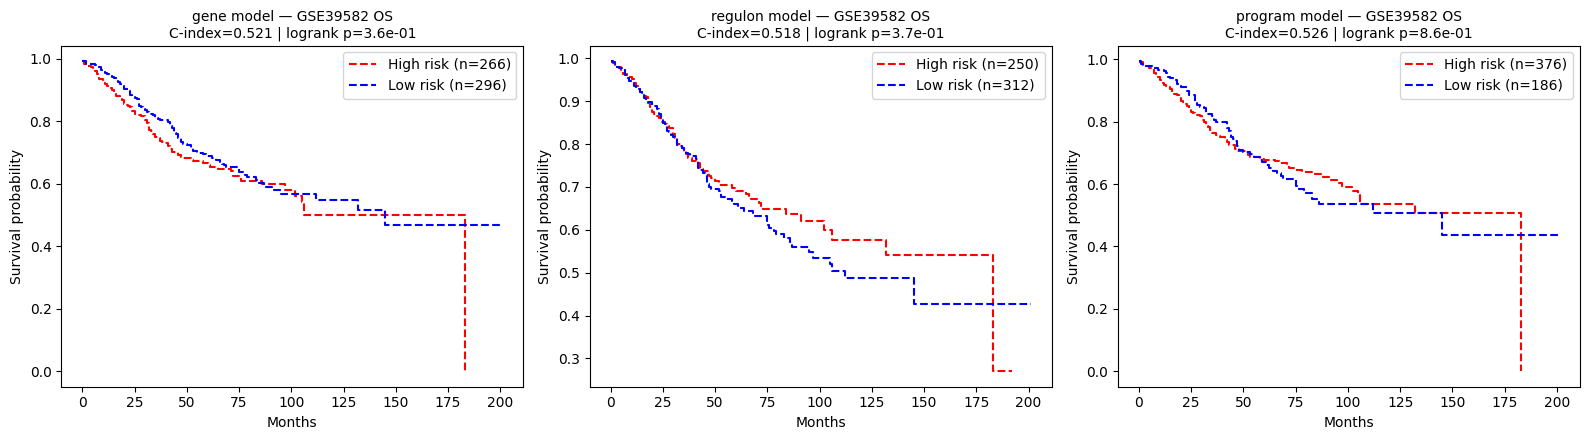

           k  alpha  TCGA_test_C (final split) TCGA_test_C mean±sd  GSE39582_OS_C  GSE39582_OS_logrank_p  GSE39582_high_risk_n
model                                                                                                                         
gene     100  500.0                     0.5497       0.575 ± 0.066         0.5213                 0.3569                   266
regulon   25    0.1                     0.5202       0.553 ± 0.083         0.5183                 0.3681                   250
program    5    0.1                     0.4006       0.539 ± 0.077         0.5257                 0.8626                   376


In [11]:
# Apply the final TCGA models to the validation cohort
if HAS_VALIDATION:
    rows = []

    # One row of panels for OS, and a second row for DSS if the cohort has it
    n_rows = 2 if HAS_DSS else 1
    fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4.5 * n_rows), squeeze=False)

    for j, m in enumerate(MODELS):
        r = final[m]

        # Predict every validation patient using only the features this model selected (no refitting)
        pred = r["ridge"].predict(X_mb[m][r["features"]].values)
        pred_s = pd.Series(pred, index=mb_patients)
        pred_s.rename(f"{m}_pred").to_csv(os.path.join(risk_dir, f"{val}_pred_{m}.csv"))

        # Overall survival: all patients
        ci_os, p_os = km_panel(axes[0, j], pred, mb_clin, 'OS_MONTHS', 'OS_STATUS', f"{m} model — {VAL_NAME} OS")
        row = {"model": m, "k": r["k"], "alpha": r["alpha"],
               "TCGA_test_C (final split)": r["test_cindex"],
               "TCGA_test_C mean±sd": f"{runs_df.loc[runs_df.model == m, 'test_cindex'].mean():.3f} ± "
                                      f"{runs_df.loc[runs_df.model == m, 'test_cindex'].std():.3f}",
               f"{VAL_NAME}_OS_C": ci_os, f"{VAL_NAME}_OS_logrank_p": p_os,
               f"{VAL_NAME}_high_risk_n": int((pred > RISK_CUTOFF).sum())}

        # Disease-specific survival: only patients with a known cause of death (DSS_STATUS not NaN)
        # Predictions and survival table are filtered with the same IDs so they stay aligned
        if HAS_DSS:
            dss_ids = mb_clin.index[mb_clin["DSS_STATUS"].notna()]
            ci_dss, p_dss = km_panel(axes[1, j], pred_s.loc[dss_ids].values, mb_clin.loc[dss_ids],
                                     'OS_MONTHS', 'DSS_STATUS', f"{m} model — {VAL_NAME} DSS (n={len(dss_ids)})")
            row.update({f"{VAL_NAME}_DSS_C": ci_dss, f"{VAL_NAME}_DSS_logrank_p": p_dss})
        rows.append(row)

    plt.tight_layout(); plt.savefig(os.path.join(risk_dir, f"km_{val}.pdf"), dpi=300); plt.show()

    # Summary table: one row per model with TCGA test C-index and validation cohort C-index and logrank p
    results = pd.DataFrame(rows).set_index("model")
    results.to_csv(os.path.join(risk_dir, "risk_model_summary.csv"))
    print(results.round(4).to_string())
else:
    # No independent cohort: the summary holds the TCGA held-out test results only
    rows = [{"model": m, "k": final[m]["k"], "alpha": final[m]["alpha"],
             "TCGA_test_C (final split)": final[m]["test_cindex"],
             "TCGA_test_C mean±sd": f"{runs_df.loc[runs_df.model == m, 'test_cindex'].mean():.3f} ± "
                                    f"{runs_df.loc[runs_df.model == m, 'test_cindex'].std():.3f}",
             "independent_cohort": "none (not externally validated)"} for m in MODELS]
    results = pd.DataFrame(rows).set_index("model")
    results.to_csv(os.path.join(risk_dir, "risk_model_summary.csv"))
    print("No independent cohort for this cancer: TCGA held-out test only")
    print(results.round(4).to_string())


In [12]:
# Program-level survival association, as in the paper (58 of its 179 programs: 7 low-risk, 51 high-risk)
# Cox regression of survival on each program's activity (-1 / 0 / +1), the same activity the program risk model uses
from lifelines import CoxPHFitter

rows = []
for prog_id in prog_act_tcga.index:
    activity = prog_act_tcga.loc[prog_id, patients]

    # A program that is neutral in (almost) every patient cannot be tested
    if (activity != 0).sum() < 5:
        rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})
        continue
    df_cox = srv.loc[patients, ["OS_MONTHS", "OS_STATUS"]].copy()
    df_cox["activity"] = activity.values
    try:
        cph = CoxPHFitter().fit(df_cox, duration_col="OS_MONTHS", event_col="OS_STATUS")
        rows.append({"program": prog_id, "HR": cph.hazard_ratios_["activity"], "p_value": cph.summary.loc["activity", "p"]})
    except Exception:
        rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})

program_cox = pd.DataFrame(rows).set_index("program").sort_index()
program_cox.to_csv(os.path.join(output_dir, "program_cox_results.csv"))

sig = program_cox[program_cox["p_value"] <= 0.05]
print(f"Programs tested: {int(program_cox['p_value'].notna().sum())} of {len(program_cox)}")
print(f"Survival-associated (Cox p <= 0.05): {len(sig)} | high-risk (HR > 1): {int((sig['HR'] > 1).sum())} | low-risk (HR < 1): {int((sig['HR'] < 1).sum())}")
print("Paper (GBM): 58 of 179 programs | 51 high-risk | 7 low-risk")

Programs tested: 215 of 216
Survival-associated (Cox p <= 0.05): 24 | high-risk (HR > 1): 5 | low-risk (HR < 1): 19
Paper (GBM): 58 of 179 programs | 51 high-risk | 7 low-risk


In [13]:
# Program-level survival association replicated in the independent cohort (needs the validation cells above and the TCGA program Cox cell)
# Same Cox regression on the same program activity (-1 / 0 / +1), built in the cohort with the same regulons, programs and threshold.
# The cohort usually has many more deaths than TCGA, so it has more power to detect a program's survival association.
# A program counts as replicated when the cohort Cox p <= 0.05 with the hazard ratio in the same direction as in TCGA.
from lifelines import CoxPHFitter

# Variable names differ between notebook copies (mb_* or ext_*); missing if this cancer has no cohort with survival data
prog_act_cohort = globals().get("prog_act_mb", globals().get("prog_act_ext"))
clin_cohort     = globals().get("mb_clin", globals().get("ext_clin"))

if prog_act_cohort is None or clin_cohort is None:
    print("No independent cohort with survival data: program Cox replication skipped")
else:
    cohort_patients = [p for p in prog_act_cohort.columns if p in clin_cohort.index]
    rows = []
    for prog_id in prog_act_cohort.index:
        activity = prog_act_cohort.loc[prog_id, cohort_patients]
        if (activity != 0).sum() < 5:
            rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})
            continue
        df_cox = clin_cohort.loc[cohort_patients, ["OS_MONTHS", "OS_STATUS"]].copy()
        df_cox["activity"] = activity.values
        df_cox = df_cox.dropna()
        try:
            cph = CoxPHFitter().fit(df_cox, duration_col="OS_MONTHS", event_col="OS_STATUS")
            rows.append({"program": prog_id, "HR": cph.hazard_ratios_["activity"], "p_value": cph.summary.loc["activity", "p"]})
        except Exception:
            rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})
    program_cox_ext = pd.DataFrame(rows).set_index("program").sort_index()
    program_cox_ext.to_csv(os.path.join(output_dir, f"{val}_program_cox_results.csv"))

    # TCGA and cohort side by side
    both = program_cox.join(program_cox_ext, lsuffix="_TCGA", rsuffix=f"_{VAL_NAME}")
    tcga_sig = both["p_value_TCGA"] <= 0.05
    ext_sig  = both[f"p_value_{VAL_NAME}"] <= 0.05
    same_dir = np.sign(np.log(both["HR_TCGA"])) == np.sign(np.log(both[f"HR_{VAL_NAME}"]))
    both["sig_TCGA"] = tcga_sig
    both[f"sig_{VAL_NAME}"] = ext_sig
    both["replicated"] = tcga_sig & ext_sig & same_dir            # significant in both, same direction
    both["sig_either"] = tcga_sig | ext_sig                        # significant in at least one cohort
    both.to_csv(os.path.join(output_dir, "program_cox_tcga_vs_validation.csv"))

    n_events = int(clin_cohort.loc[cohort_patients, "OS_STATUS"].sum())
    ext_only = both[ext_sig]
    print(f"{VAL_NAME}: {len(cohort_patients)} patients, {n_events} deaths | programs tested: {int(program_cox_ext['p_value'].notna().sum())}")
    print(f"Survival-associated in {VAL_NAME} (Cox p <= 0.05): {len(ext_only)} | high-risk: {int((ext_only[f'HR_{VAL_NAME}'] > 1).sum())} "
          f"| low-risk: {int((ext_only[f'HR_{VAL_NAME}'] < 1).sum())}")
    print(f"Survival-associated in TCGA: {int(tcga_sig.sum())} | in both, same direction: {int(both['replicated'].sum())} "
          f"| in either cohort: {int(both['sig_either'].sum())}")

GSE39582: 562 patients, 191 deaths | programs tested: 214
Survival-associated in GSE39582 (Cox p <= 0.05): 24 | high-risk: 10 | low-risk: 14
Survival-associated in TCGA: 24 | in both, same direction: 5 | in either cohort: 43


In [14]:
# Program Cox in the independent cohort on disease-specific survival (DSS): only deaths from the cancer count as events,
# deaths from other causes are censored and patients with an unknown cause of death are left out.
# Long-followed, older cohorts (METABRIC) have many deaths from other causes, which dilute the survival signal.
# Needs the cell above. Skipped if the cohort records no cause of death.
if prog_act_cohort is None or clin_cohort is None or "DSS_STATUS" not in clin_cohort.columns:
    print("No disease-specific survival in the independent cohort: DSS program Cox skipped")
else:
    dss_patients = [p for p in cohort_patients if pd.notna(clin_cohort.loc[p, "DSS_STATUS"])]
    rows = []
    for prog_id in prog_act_cohort.index:
        activity = prog_act_cohort.loc[prog_id, dss_patients]
        if (activity != 0).sum() < 5:
            rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})
            continue
        df_cox = clin_cohort.loc[dss_patients, ["OS_MONTHS", "DSS_STATUS"]].copy()
        df_cox["activity"] = activity.values
        df_cox = df_cox.dropna()
        try:
            cph = CoxPHFitter().fit(df_cox, duration_col="OS_MONTHS", event_col="DSS_STATUS")
            rows.append({"program": prog_id, "HR": cph.hazard_ratios_["activity"], "p_value": cph.summary.loc["activity", "p"]})
        except Exception:
            rows.append({"program": prog_id, "HR": np.nan, "p_value": np.nan})
    program_cox_dss = pd.DataFrame(rows).set_index("program").sort_index()
    program_cox_dss.to_csv(os.path.join(output_dir, f"{val}_program_cox_dss_results.csv"))

    # Added to the side-by-side table of the cell above
    both[f"HR_{VAL_NAME}_DSS"] = program_cox_dss["HR"]
    both[f"p_value_{VAL_NAME}_DSS"] = program_cox_dss["p_value"]
    dss_sig = both[f"p_value_{VAL_NAME}_DSS"] <= 0.05
    dss_same_dir = np.sign(np.log(both["HR_TCGA"])) == np.sign(np.log(both[f"HR_{VAL_NAME}_DSS"]))
    both[f"sig_{VAL_NAME}_DSS"] = dss_sig
    both["replicated_DSS"] = tcga_sig & dss_sig & dss_same_dir
    both["sig_either_DSS"] = tcga_sig | dss_sig
    both.to_csv(os.path.join(output_dir, "program_cox_tcga_vs_validation.csv"))

    n_dss = int(clin_cohort.loc[dss_patients, "DSS_STATUS"].sum())
    print(f"{VAL_NAME} DSS: {len(dss_patients)} patients (cause of death known or alive), {n_dss} disease-specific deaths "
          f"(OS: {n_events} deaths)")
    print(f"Survival-associated in {VAL_NAME}, DSS: {int(dss_sig.sum())} | high-risk: {int((dss_sig & (both[f'HR_{VAL_NAME}_DSS'] > 1)).sum())} "
          f"| low-risk: {int((dss_sig & (both[f'HR_{VAL_NAME}_DSS'] < 1)).sum())}   (OS: {int(ext_sig.sum())})")
    print(f"In TCGA and {VAL_NAME} DSS, same direction: {int(both['replicated_DSS'].sum())} (OS: {int(both['replicated'].sum())}) "
          f"| in either: {int(both['sig_either_DSS'].sum())} (OS: {int(both['sig_either'].sum())})")

No disease-specific survival in the independent cohort: DSS program Cox skipped
